In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import mutual_info_score
from sklearn.linear_model import LogisticRegression

In [2]:
URL = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(URL)

In [3]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [5]:
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='object')

# Data Preparation

Check if the missing values are presented in the features.

In [6]:
num_feat = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score',]
cat_feat = df.select_dtypes(exclude='number').columns.to_list()

In [7]:
num_feat

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [8]:
cat_feat

['lead_source', 'industry', 'employment_status', 'location']

In [9]:
df.isna().sum()

,0
lead_source,148
industry,240
employment_status,194
location,208
annual_income,369
number_of_courses_viewed,0
interaction_count,0
lead_score,35
converted,0


handle missing values

In [10]:
df[cat_feat] = df[cat_feat].fillna('NA')

In [11]:
df[num_feat] = df[num_feat].fillna(0.0)

In [12]:
df.isna().sum()

,0
lead_source,0
industry,0
employment_status,0
location,0
annual_income,0
number_of_courses_viewed,0
interaction_count,0
lead_score,0
converted,0


# Question 1
What is the most frequent observation (mode) for the column industry?

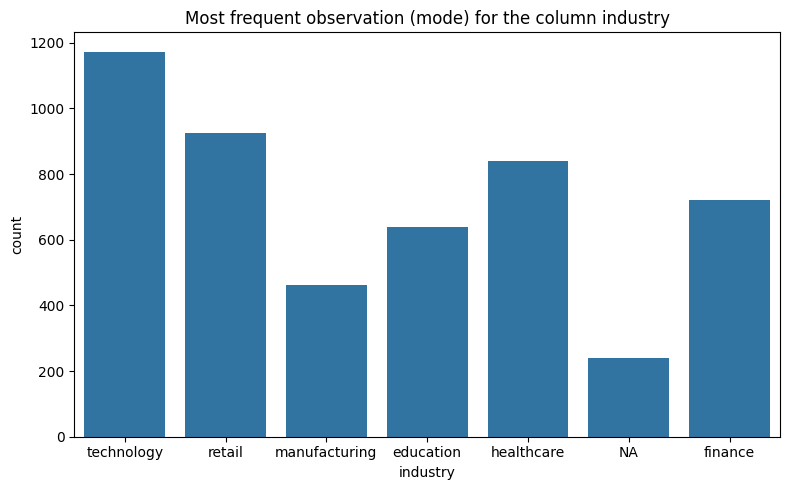

,count
industry,
technology,1173
retail,925
healthcare,840
finance,720
education,639
manufacturing,463
NA,240


In [13]:
plt.figure(figsize=(8,5))
sns.countplot(x='industry', data=df)
plt.title('Most frequent observation (mode) for the column industry')
plt.tight_layout()
plt.show()
df['industry'].value_counts().T

`asnwer = technology`

# Question 2
What are the two features that have the biggest correlation?

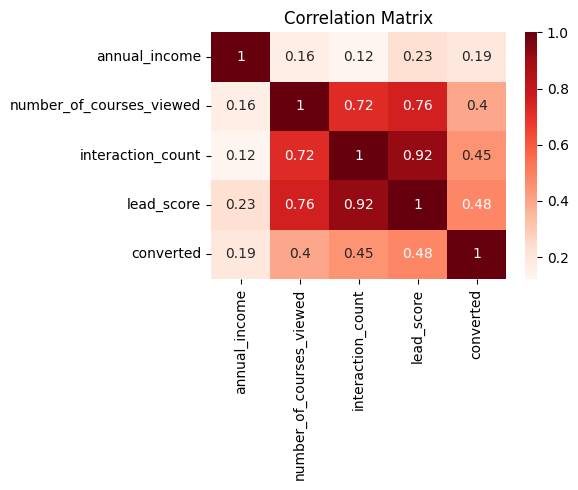

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
annual_income,1.000000,0.161300,0.122842,0.229496,0.189652
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204,0.395038
interaction_count,0.122842,0.721609,1.000000,0.915746,0.448624
lead_score,0.229496,0.757204,0.915746,1.000000,0.483246
converted,0.189652,0.395038,0.448624,0.483246,1.000000


In [14]:
plt.figure(figsize=(6,5))
sns.heatmap(df.corr(numeric_only=True), cmap='Reds', annot=True)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

df.corr(numeric_only=True)

`answer = interaction_count and lead_score`

# Split the data

In [15]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [16]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [17]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[cat_feat].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[cat_feat].to_dict(orient='records')
X_val = dv.transform(val_dict)

# Question 3
* Calculate the mutual information score between converted and other categorical variables in the dataset. Use the training set only.
* Round the scores to 2 decimals using round(score, 2).

Which of these variables has the biggest mutual information score?

In [18]:
mutual_info_score(df_full_train.converted, df_full_train.industry)

np.float64(0.0028984818739526547)

In [19]:
mutual_info_score(df_full_train.converted, df_full_train.location)

np.float64(0.0010498214288891111)

In [20]:
mutual_info_score(df_full_train.converted, df_full_train.lead_source)

np.float64(0.0347609795100606)

In [21]:
mutual_info_score(df_full_train.converted, df_full_train.employment_status)

np.float64(0.02031283511067701)

`answer = lead_source`

# Question 4
* Now let's train a logistic regression.
* Remember that we have several categorical variables in the dataset. Include them using one-hot encoding.
* Fit the model on the training dataset.
    * To make sure the results are reproducible across different versions of Scikit-Learn, fit the model with these parameters:
    * model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
* Calculate the accuracy on the validation dataset and round it to 2 decimal digits.

What accuracy did you get?

What accuracy did you get?

In [36]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)
val_acc = model.score(X_val, y_val)
val_acc

0.655

In [23]:
model.coef_

array([[ 1.47178350e-01,  5.80516382e-01,  1.36504605e-01,
        -4.99590739e-01, -3.23713092e-01,  6.39408928e-02,
        -2.17130419e-01,  1.55490868e-01, -3.31120276e-02,
        -1.51063694e-01, -4.57353118e-04,  2.23227239e-01,
         1.39067561e-01, -7.11012873e-01,  4.67973929e-01,
        -6.19999380e-01,  9.17483309e-01, -1.52617038e-01,
         1.97222721e-01, -1.40403354e-01,  4.87983677e-02,
         1.21791870e-01,  6.17321099e-02, -2.48246209e-01]])

`answer = 0.65`

# Question 5
* Let's find the least useful feature using the feature elimination technique.
* Train a model using the same features and parameters as in Q4 (without rounding).
* Now exclude each feature from this set and train a model without it. Record the accuracy for each model.
* For each feature, calculate the difference between the original accuracy and the accuracy without the feature.

Which of following feature has the smallest difference?

In [24]:
small = ['lead_source', 'number_of_courses_viewed', 'interaction_count']

In [25]:
df_train[small].iloc[:10].to_dict(orient='records')

[{'lead_source': 'paid_ads',
  'number_of_courses_viewed': 2,
  'interaction_count': 3},
 {'lead_source': 'events',
  'number_of_courses_viewed': 0,
  'interaction_count': 0},
 {'lead_source': 'referral',
  'number_of_courses_viewed': 2,
  'interaction_count': 5},
 {'lead_source': 'organic_search',
  'number_of_courses_viewed': 2,
  'interaction_count': 2},
 {'lead_source': 'events',
  'number_of_courses_viewed': 1,
  'interaction_count': 5},
 {'lead_source': 'paid_ads',
  'number_of_courses_viewed': 2,
  'interaction_count': 3},
 {'lead_source': 'organic_search',
  'number_of_courses_viewed': 3,
  'interaction_count': 8},
 {'lead_source': 'organic_search',
  'number_of_courses_viewed': 0,
  'interaction_count': 1},
 {'lead_source': 'organic_search',
  'number_of_courses_viewed': 1,
  'interaction_count': 5},
 {'lead_source': 'events',
  'number_of_courses_viewed': 3,
  'interaction_count': 7}]

In [26]:
dicts_train_small = df_train[small].to_dict(orient='records')
dicts_val_small = df_val[small].to_dict(orient='records')

In [27]:
dv_small = DictVectorizer(sparse=False)
dv_small.fit(dicts_train_small)

DictVectorizer(sparse=False)

In [28]:
dv_small.get_feature_names_out()

array(['interaction_count', 'lead_source=NA', 'lead_source=events',
       'lead_source=organic_search', 'lead_source=paid_ads',
       'lead_source=referral', 'lead_source=social_media',
       'number_of_courses_viewed'], dtype=object)

In [29]:
X_train_small = dv_small.transform(dicts_train_small)

In [30]:
model_small = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model_small.fit(X_train_small, y_train)

LogisticRegression(max_iter=1000, random_state=42, solver='liblinear')

In [31]:
w0 = model_small.intercept_[0]
w0

np.float64(-1.5017906156855507)

In [32]:
w = model_small.coef_[0]
w.round(3)

array([ 0.345, -0.184, -0.565, -0.031, -0.596,  0.191, -0.317,  0.283])

In [33]:
dict(zip(dv_small.get_feature_names_out(), w.round(3)))

{'interaction_count': np.float64(0.345),
 'lead_source=NA': np.float64(-0.184),
 'lead_source=events': np.float64(-0.565),
 'lead_source=organic_search': np.float64(-0.031),
 'lead_source=paid_ads': np.float64(-0.596),
 'lead_source=referral': np.float64(0.191),
 'lead_source=social_media': np.float64(-0.317),
 'number_of_courses_viewed': np.float64(0.283)}

In [ ]:
all_features = num_feat + cat_feat

train_dict = df_train[all_features].to_dict(orient='records')
val_dict = df_val[all_features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)
baseline_acc = model.score(X_val, y_val)
print(f"Baseline Accuracy: {baseline_acc:.5f}\n")

# feature elimination loop
features_to_check = ['number_of_courses_viewed', 'lead_source', 'interaction_count']

for col in features_to_check:
    # drop one fitur
    subset = [f for f in all_features if f != col]
    
    # subset vectorization
    train_dict_sub = df_train[subset].to_dict(orient='records')
    val_dict_sub = df_val[subset].to_dict(orient='records')
    
    dv_sub = DictVectorizer(sparse=False)
    X_train_sub = dv_sub.fit_transform(train_dict_sub)
    X_val_sub = dv_sub.transform(val_dict_sub)
    
    # fit model
    model_sub = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    model_sub.fit(X_train_sub, y_train)
    
    # Evaluation
    acc_sub = model_sub.score(X_val_sub, y_val)
    diff = baseline_acc - acc_sub
    
    print(f"{col} -> accuracy: {acc_sub:.5f}, diff: {diff:.5f}")

Baseline Accuracy: 0.64500

number_of_courses_viewed -> accuracy: 0.64300, diff: 0.00200
lead_source -> accuracy: 0.64200, diff: 0.00300
interaction_count -> accuracy: 0.60100, diff: 0.04400


`answer = number_of_courses_viewed `

# Question 6
* Now let's train a regularized logistic regression.
* Let's try the following values of the parameter C: [0.000001, 0.00001, 0.0001, 0.001].
* Train models using all the features as in Q4.
* Calculate the accuracy on the validation dataset and round it to 3 decimal digits.

Which of these C leads to the best accuracy on the validation set?

In [47]:
C_values = [0.000001, 0.00001, 0.0001, 0.001]

for C in C_values:
    # Latih model dengan masing-masing nilai C
    model_reg = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=42)
    model_reg.fit(X_train, y_train)
    
    # Hitung akurasi pada data validasi
    acc = model_reg.score(X_val, y_val)
    
    # Cetak hasil dengan pembulatan 3 angka di belakang koma
    print(f"C = {C} -> accuracy: {acc:.3f}")

C = 1e-06 -> accuracy: 0.598
C = 1e-05 -> accuracy: 0.598
C = 0.0001 -> accuracy: 0.613
C = 0.001 -> accuracy: 0.645


`answer = 0.001 `